# 07 · A tour of the `opal` command line

Every feature is available from the shell; the Python API is the same code underneath. This notebook runs each
command with `!` so its console output is kept below it. Settings are small (128², a few hundred ticks) so the
whole tour takes a few minutes. In a terminal, drop the `!`.

| Command | Does | README |
|---|---|---|
| `opal info` | GPU / TensorFlow / RAM status | §1.3 |
| `opal config` | print, validate and save a resolved configuration | §3 |
| `opal plan` | memory-guard dry run | §4 |
| `opal run` | simulate and save the received fields | §2, §4, §5.1, §6 |
| `opal analyze` | fiber coupling or r₀ per frame | §8 |
| `opal view` | interactive viewer, or render PNG/GIF/MP4 | §9 |
| `opal pass` | satellite pass with exact r₀ switching | §5.2 |
| `opal dataset` | labelled ML dataset | §7 |
| `opal export` | TensorFlow SavedModel | §10 |

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

from IPython.display import Image, display

Path("runs/cli_tour").mkdir(parents=True, exist_ok=True)

OPAL 1.1.0


In [2]:
!opal --version
!opal --help

opal 1.1.0


usage: opal [-h] [--version] command ...

OPAL: GPU-accelerated multilayer atmospheric turbulence simulator for space-
to-ground optical links.

positional arguments:
  command
    info      show GPU / TensorFlow / RAM status
    config    print or save the resolved configuration
    plan      memory-guard dry run: which mode would run and why
    run       simulate and save the received fields
    pass      satellite pass with exact per-segment r0 switching
    dataset   generate a labelled ML dataset
    analyze   fiber coupling / r0 per frame of a saved run
    export    export a TensorFlow SavedModel
    view      interactive viewer for runs, passes and datasets

optional arguments:
  -h, --help  show this help message and exit
  --version   show program's version number and exit

Run `opal <command> -h` for the options of a command. Errors are reported
without a traceback; set OPAL_DEBUG=1 to see it.


In [3]:
!opal info

OPAL 1.1.0
python 3.9.23 | numpy 1.24.2 | tensorflow 2.10.1
built with CUDA: True
GPU: NVIDIA GeForce RTX 4080 (16.0 GiB)
host RAM available: 34.0 GiB
default output folders: <repo>\runs, datasets, exports


## 1. Configuration

`opal config` applies defaults, the `-c` file and the overrides, validates the result, prints it, and with
`-o` saves it as a new config file. `--grid`, `--layers`, `--r0`, `--seed` and `--steps` are shortcuts;
`--set KEY=VALUE` reaches every other parameter (README §3.4).

In [4]:
!opal config -c configs/quickstart_256.json --grid 128 --layers 6 --steps 300 --set wind=8 -o runs/cli_tour/tour.json

wrote runs/cli_tour/tour.json


Mistakes are caught before anything is built, with a suggestion:

In [5]:
!opal config -c configs/quickstart_256.json --set channel_params.satelite_zenith_angle=30 2>&1
!opal config -c configs/quickstart_256.json --set pass_params.num_segment=20 2>&1
!opal config -c configs/quickstart_256.json --grid 255 2>&1

opal config: error: Unknown parameter 'channel_params.satelite_zenith_angle'; did you mean 'channel_params.satellite_zenith_angle'?


opal config: error: Unknown parameter 'pass_params.num_segment'; did you mean 'pass_params.num_segments'?


opal config: error: phase_screen_size must be an even integer >= 16, got 255


## 2. Plan, then run

`opal plan` builds the simulator, measures its memory and says which mode `opal run` would use, without
simulating. Here it is asked about a 100 000-tick run of the tour channel.

In [6]:
!opal plan -c runs/cli_tour/tour.json --steps 100000

OPAL 1.1.0 | N=128 layers=6 r0=0.1 m D/r0=12.8 seed=1
[opal    1.71s] startup 1.7 s (Python, NumPy/SciPy and TensorFlow import)
[opal    1.89s] building simulator: N=128, 6 layers (per-layer covariance, Cholesky and SVD on the CPU; done once per run)
[opal    6.85s] built simulator in 5.0 s | extrusion 154 rows/tick over all layers (wind multiplier x2; per-layer table: opal plan)
memory plan: N=128 steps=100000 requested=auto -> host
  frame 0.1 MiB | output 12.21 GiB | baseline 0.01 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 32.33 GiB
  predicted GPU peak: device 27.62 GiB (too big) | host 3.20 GiB | chunked 3.23 GiB (chunk<=100)
  decision: auto: streaming frames to host keeps GPU memory flat -> host
channel: N=128 dx=0.01 m aperture=1.28 m r0=0.1 m D/r0=12.8 layers=6 seed=1
  layer=0  height_m=165.2  r0_m=0.1196  wind_mps=10.82  cn2=1.189e-14  rows_per_tick=1.082  seed=1016164991  rows_extruded=3  effective_wind_mps=30
  layer=1  height_m=918.5  r0_m=0.266  wind_mps=20.89  cn

Without `-o`, `opal run` writes to a new folder `runs/<date>_<time>_N.._L.._r0-.._T.._seed..`. The last lines
split the wall time into start-up, build and simulation (README §2.3).

In [7]:
!opal run -c runs/cli_tour/tour.json

RUN = max(Path("runs").glob("*_N128_L6_r0-0.1_T300_seed1"), key=lambda p: p.stat().st_mtime).as_posix()
print("\nrun directory:", RUN)

OPAL 1.1.0 | N=128 layers=6 r0=0.1 m D/r0=12.8 seed=1
[opal    0.06s] output: runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1
[opal    1.68s] startup 1.7 s (Python, NumPy/SciPy and TensorFlow import)
[opal    1.84s] building simulator: N=128, 6 layers (per-layer covariance, Cholesky and SVD on the CPU; done once per run)
[opal    5.17s] built simulator in 3.3 s | extrusion 154 rows/tick over all layers (wind multiplier x2; per-layer table: opal plan)
[opal    8.91s] memory plan: N=128 steps=300 requested=auto -> device
[opal    8.91s]   frame 0.1 MiB | output 0.04 GiB | baseline 0.01 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 32.31 GiB
[opal    8.91s]   predicted GPU peak: device 3.28 GiB | host 3.20 GiB | chunked 3.23 GiB (chunk<=100)
[opal    8.91s] guard: auto: full output fits on the GPU -> device
[opal    8.93s] running device mode: 300 steps, N=128, 6 layers
[opal   64.64s] device: 300 steps in 55.69 s (185.64 ms/step)
[opal   64.68s] wrote frames.npy (0.04 GiB) in 0.0 s


## 3. Analyze

`opal analyze r0|fiber RUN` measures every selected frame and writes `RUN/analysis/<what>.csv`,
`<what>_summary.json` and, with `--plot`, `<what>.png`. Frames are read in bounded batches, so any run size is
safe. `--frames 20` (the default) picks 20 evenly spaced frames; `--frames all` takes every one.

[opal    0.41s] r0: 300 of 300 frames from run output runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1 (0.04 GiB to read, 1024 frames per batch, <= 256 MiB RAM)
r0 over 300 frames: median 0.1184 m, mean 0.1195 m, std 0.0130 m (median ratio to configured path r0 0.1 m: 1.184)
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\r0.csv
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\r0.png
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\r0_summary.json
note: frames of one run are correlated in time; for ensemble statistics use independent realizations (opal dataset -k K or GpuSimulator.reseed)


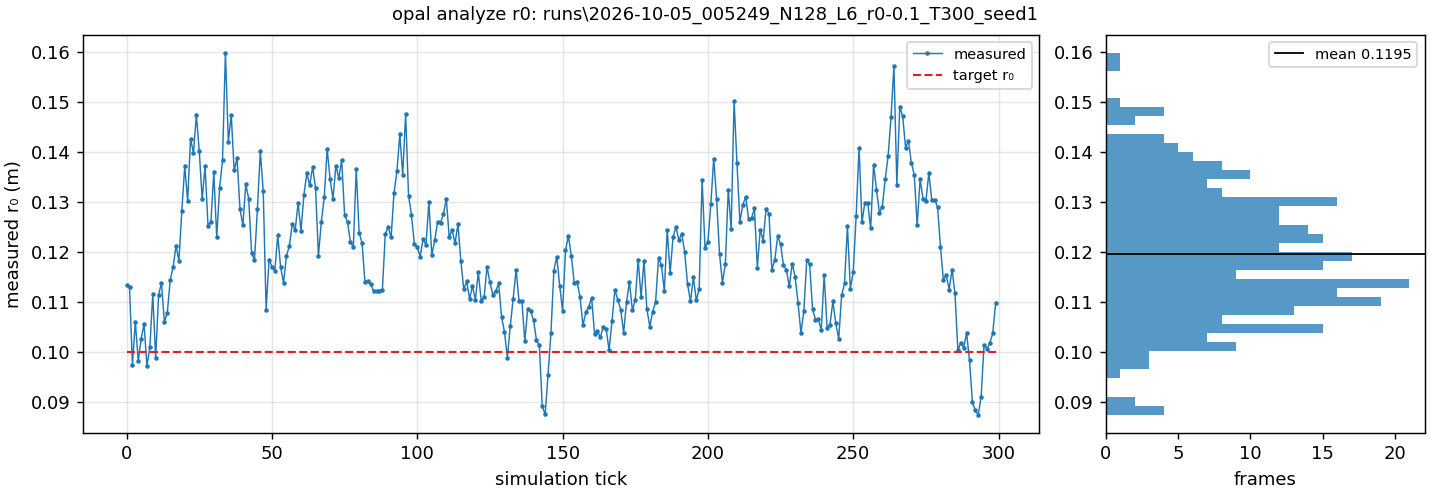

In [8]:
!opal analyze r0 {RUN} --frames all --plot
display(Image(filename=f"{RUN}/analysis/r0.png", width=640))

[opal    0.38s] fiber: 300 of 300 frames from run output runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1 (0.04 GiB to read, 512 frames per batch, <= 256 MiB RAM)
fiber coupling over 300 frames (D=0.512 m, D/r0=5.12, a=1.12): mean 0.0600, std 0.0660, min 0.0006, max 0.4245; von Karman theory 0.0434 (+38.4 %)
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\fiber.csv
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\fiber.png
wrote runs\2026-10-05_005249_N128_L6_r0-0.1_T300_seed1\analysis\fiber_summary.json
note: frames of one run are correlated in time; for ensemble statistics use independent realizations (opal dataset -k K or GpuSimulator.reseed)


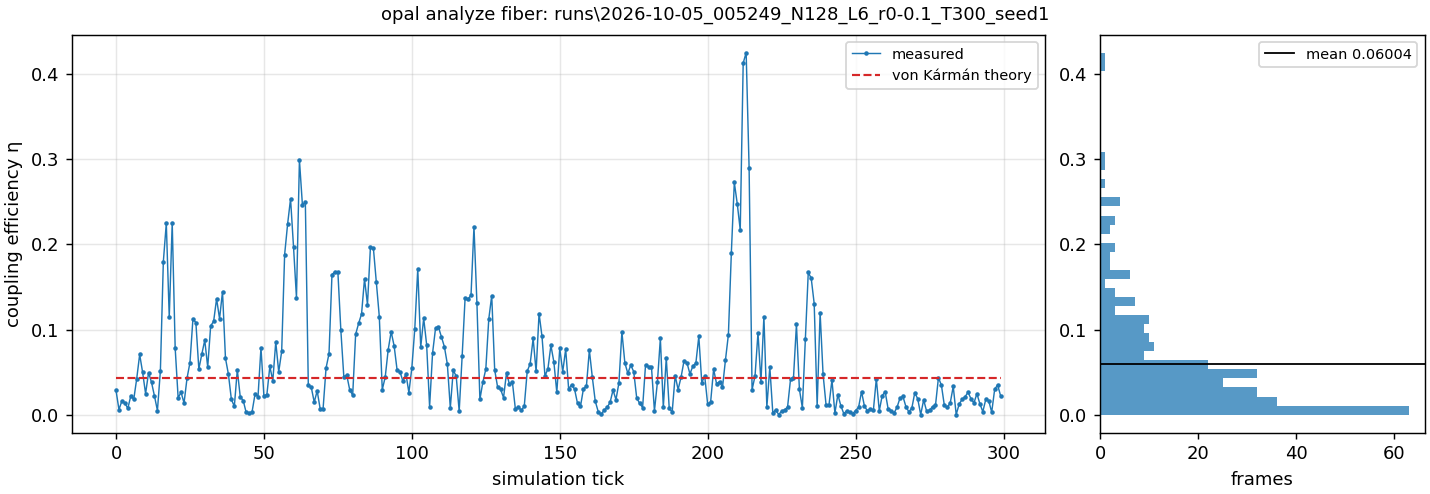

In [9]:
!opal analyze fiber {RUN} --frames all --plot
display(Image(filename=f"{RUN}/analysis/fiber.png", width=640))

In [10]:
import json

print("".join(open(f"{RUN}/analysis/fiber.csv").readlines()[:5]))
summary = json.loads(Path(f"{RUN}/analysis/fiber_summary.json").read_text())
print({k: summary[k] for k in ("frames_analysed", "aperture_m", "D_over_r0", "statistics", "theory")})

frame,step,eta
0,0,0.028945806
1,1,0.0064544984
2,2,0.016726578
3,3,0.014001662

{'frames_analysed': 300, 'aperture_m': 0.512, 'D_over_r0': 5.12, 'statistics': {'count': 300, 'mean': 0.0600382830539296, 'std': 0.06603151788476905, 'median': 0.03946029386421258, 'min': 0.0005631880836151772, 'max': 0.42447041674108194, 'p05': 0.003975515616253704, 'p95': 0.1967961991362734}, 'theory': {'model': 'von Karman, configured r0', 'eta': 0.04338840687706023, 'deviation_percent': 38.37402056278836}}


Two things to keep in mind when reading these numbers:

- On a 128² grid the r₀ estimator reads high (README §5.2), so a median ratio of about 1.2 here is expected.
  Larger grids bring it to 1.
- 300 consecutive ticks of one run are only a few independent looks at the turbulence, so the mean coupling
  can be well off the von Kármán value, as the closing note in the output says. Notebook 06 compares with
  theory properly, using independent realizations.

## 4. View

`opal view RUN` opens an interactive window (play/pause, slider, step, jump to a tick, snapshots); with `--save`
it renders a PNG of one frame or a GIF/MP4 instead (README §9). Analysis results are drawn as a strip under the
frames.

wrote runs\cli_tour\frame150.png


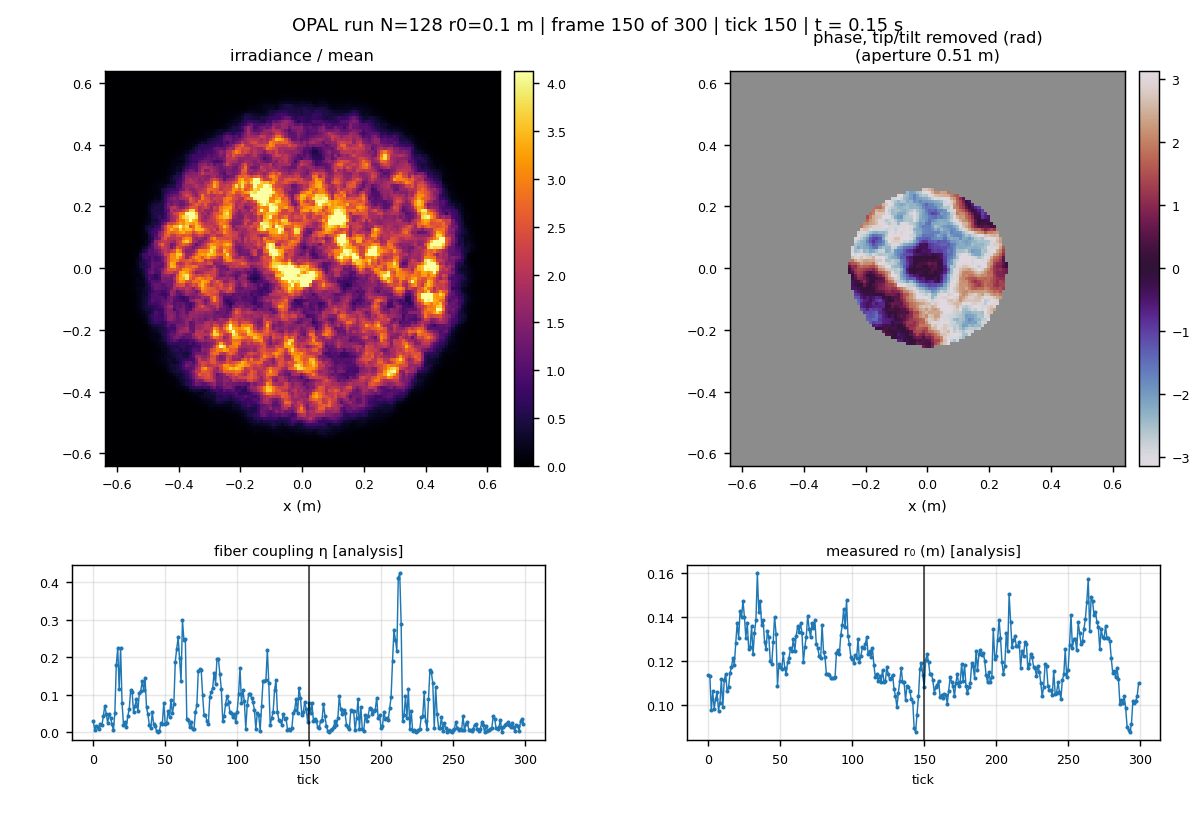

In [11]:
!opal view {RUN} --tick 150 --views intensity,phase_tt --save runs/cli_tour/frame150.png
display(Image(filename="runs/cli_tour/frame150.png", width=720))

In [12]:
!opal view {RUN} --views intensity --no-series --stride 6 --max-frames 50 --fps 10 --save runs/cli_tour/view.gif

# the full-size render is a few MB; keep a smaller copy for this page
from PIL import Image as PILImage, ImageSequence

src = PILImage.open("runs/cli_tour/view.gif")
scale = 360 / src.width
small = [f.convert("RGB").resize((360, round(src.height * scale)), PILImage.LANCZOS).quantize(colors=32)
         for f in ImageSequence.Iterator(src)]
small[0].save("examples/media/07_cli_view.gif", save_all=True, append_images=small[1:],
              duration=src.info.get("duration", 100), loop=0, optimize=True)
for p in ("runs/cli_tour/view.gif", "examples/media/07_cli_view.gif"):
    print(f"{p}: {Path(p).stat().st_size / 1024:.0f} KiB")

rendered 5/50 frames
rendered 10/50 frames
rendered 15/50 frames
rendered 20/50 frames
rendered 25/50 frames
rendered 30/50 frames
rendered 35/50 frames
rendered 40/50 frames
rendered 45/50 frames
rendered 50/50 frames
wrote runs\cli_tour\view.gif


runs/cli_tour/view.gif: 4325 KiB
examples/media/07_cli_view.gif: 634 KiB


![opal view --save: the irradiance of the tour run](media/07_cli_view.gif)

## 5. A satellite pass and a dataset

Both use the same flags as `run`, plus their own (see notebooks 04 and 05). The pass here is cut down to 256² and
four segments, so its measured/target r₀ ratio sits a little above 1 for the reasons explained in notebook 04.

In [13]:
!opal pass -c configs/leo_pass_b2.json --grid 256 --steps 400 --segments 4 --captures 20 -o runs/cli_tour/pass

OPAL 1.1.0 | N=256 layers=10 r0=0.25 m D/r0=10.2 seed=20260716
[opal    0.05s] output: runs\cli_tour\pass
[opal    1.54s] startup 1.5 s (Python, NumPy/SciPy and TensorFlow import)
[opal    1.72s] pass: 700 km orbit, elevation 20.0-89.9 deg over 400 s
[opal    1.72s] schedule: 4 segments x 100 steps = 400, path r0 0.131-0.250 m, 20 wavefront captures
[opal    1.72s] building simulator: N=256, 10 layers
[opal    7.60s] built simulator in 5.9 s
[opal    7.60s] seed 20260716
[opal   43.92s] segment   1/4 elev  28.6 deg target r0 0.161 m measured 0.182 m (5 captures, 36.30 s)
[opal   67.42s] segment   2/4 elev  61.8 deg target r0 0.231 m measured 0.243 m (5 captures, 23.50 s)
[opal   97.23s] segment   3/4 elev  61.2 deg target r0 0.231 m measured 0.271 m (5 captures, 29.81 s)
[opal  120.99s] segment   4/4 elev  28.5 deg target r0 0.161 m measured 0.193 m (5 captures, 23.76 s)
[opal  121.02s] done: 400 steps in 113.4 s | peak GPU 0.04 GiB | measured/theory r0 median 1.145
[opal  121.02s] wro

In [14]:
!opal dataset -c runs/cli_tour/tour.json --steps 20 --sweep r0=0.05,0.1 -k 2 --stride 5 --crop 64 -o runs/cli_tour/dataset

OPAL 1.1.0 | N=128 layers=6 r0=0.1 m D/r0=12.8 seed=1
[opal    0.49s] output: runs\cli_tour\dataset
[opal    1.90s] startup 1.9 s (Python, NumPy/SciPy and TensorFlow import)
[opal    1.90s] dataset: 2 sweep points x 2 realizations = 4 samples, 20 ticks (stride 5, 4 frames), targets intensity, phase
[opal    1.91s] building simulator: N=128, 6 layers
[opal    4.67s] built simulator in 2.8 s (reused for every realization of this sweep point via reseed)
[opal    9.41s] sample 1/4 [r0=0.05] seed 1835504127: 4.72 s | r0 0.054 m | eta 0.002 | SI 0.241
[opal   14.10s] sample 2/4 [r0=0.05] seed 1501029259: 4.56 s | r0 0.047 m | eta 0.026 | SI 0.227
[opal   14.21s] building simulator: N=128, 6 layers
[opal   18.08s] built simulator in 3.9 s (reused for every realization of this sweep point via reseed)
[opal   26.10s] sample 3/4 [r0=0.1] seed 1189033389: 8.00 s | r0 0.119 m | eta 0.011 | SI 0.135
[opal   30.02s] sample 4/4 [r0=0.1] seed 1639030180: 3.71 s | r0 0.128 m | eta 0.133 | SI 0.148
[opa

## 6. Export a SavedModel and run it

`opal export` writes the compiled channel as a TensorFlow SavedModel: the operators, the initial screens and
the RNG state, with no OPAL code needed to run it from TensorFlow (README §10). `opal run --model` runs it; with
the same seed it reproduces the run from the config.

In [15]:
!opal export -c runs/cli_tour/tour.json -o runs/cli_tour/model
!opal run --model runs/cli_tour/model --steps 50 -o runs/cli_tour/from_model

same = np.array_equal(opal.load_frames("runs/cli_tour/from_model"), opal.load_frames(RUN)[:50])
print("\nSavedModel run == first 50 ticks of the config run:", same)

OPAL 1.1.0 | N=128 layers=6 r0=0.1 m D/r0=12.8 seed=1
[opal    0.05s] output: runs\cli_tour\model
[opal    1.56s] startup 1.6 s (Python, NumPy/SciPy and TensorFlow import)
[opal    1.72s] building simulator: N=128, 6 layers (per-layer covariance, Cholesky and SVD on the CPU; done once per run)
[opal    4.36s] built simulator in 2.6 s | extrusion 154 rows/tick over all layers (wind multiplier x2; per-layer table: opal plan)
[opal   10.39s] exported SavedModel (seed 1) to runs\cli_tour\model
[opal   10.39s] total wall time 10.4 s = startup 1.6 + build 2.6 + export 6.0 + other 0.2 s


[opal    1.52s] startup 1.5 s (Python, NumPy/SciPy and TensorFlow import)
[opal    3.30s] loaded SavedModel runs/cli_tour/model in 1.6 s
[opal    3.30s] output: runs\cli_tour\from_model
[opal    5.17s] memory plan: N=128 steps=50 requested=auto -> device
[opal    5.17s]   frame 0.1 MiB | output 0.01 GiB | baseline 0.01 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 33.31 GiB
[opal    5.17s]   predicted GPU peak: device 3.22 GiB | host 3.20 GiB | chunked 3.22 GiB (chunk<=50)
[opal    5.17s] guard: auto: full output fits on the GPU -> device
[opal    5.17s] running device mode: 50 steps, N=128, 6 layers
[opal   11.65s] device: 50 steps in 6.49 s (129.73 ms/step)
[opal   11.65s] wrote frames.npy (0.01 GiB) in 0.0 s
[opal   11.67s] done: 50 steps simulated in 6.49 s | 7.7 steps/s | peak GPU 0.02 GiB
[opal   11.67s] wrote runs\cli_tour\from_model\manifest.json
[opal   11.67s] total wall time 11.7 s = startup 1.5 + load 1.6 + plan (1 traced test step) 1.9 + simulate 6.5 + other 0.2 s
[opa

## 7. Scripting

`-q` prints a single JSON line, convenient for scripts and benchmarks; `--no-save` discards the frames.

In [16]:
!opal run -c runs/cli_tour/tour.json --steps 200 --no-save -q

{"mode": "device", "steps": 200, "run_time_s": 38.164, "total_s": 46.255, "out_dir": null}
